In [2]:
import autoroot
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from paper_plots.plot_config import set_plot_style

# --- Configuration ---
font_size = 40
figsize = (12, 8)

set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette='tab20')

T = 1024
ALPHA_EXP = 0.42857139   # fixed internal alpha for exp component
ALPHA_IMP = 1.0           # fixed internal alpha for impulse component
IMP_POS = int(np.floor(ALPHA_IMP * (T // 2)))  # = 512

def mix_exp_impulse(s, beta):
    """(1-beta)*rho_exp + beta*rho_impulse, both at fixed max-alpha."""
    rho_exp = np.exp(-s / ALPHA_EXP)
    rho_imp = ((s > IMP_POS - 0.5) & (s < IMP_POS + 0.5)).astype(float)
    return (1 - beta) * rho_exp + beta * rho_imp

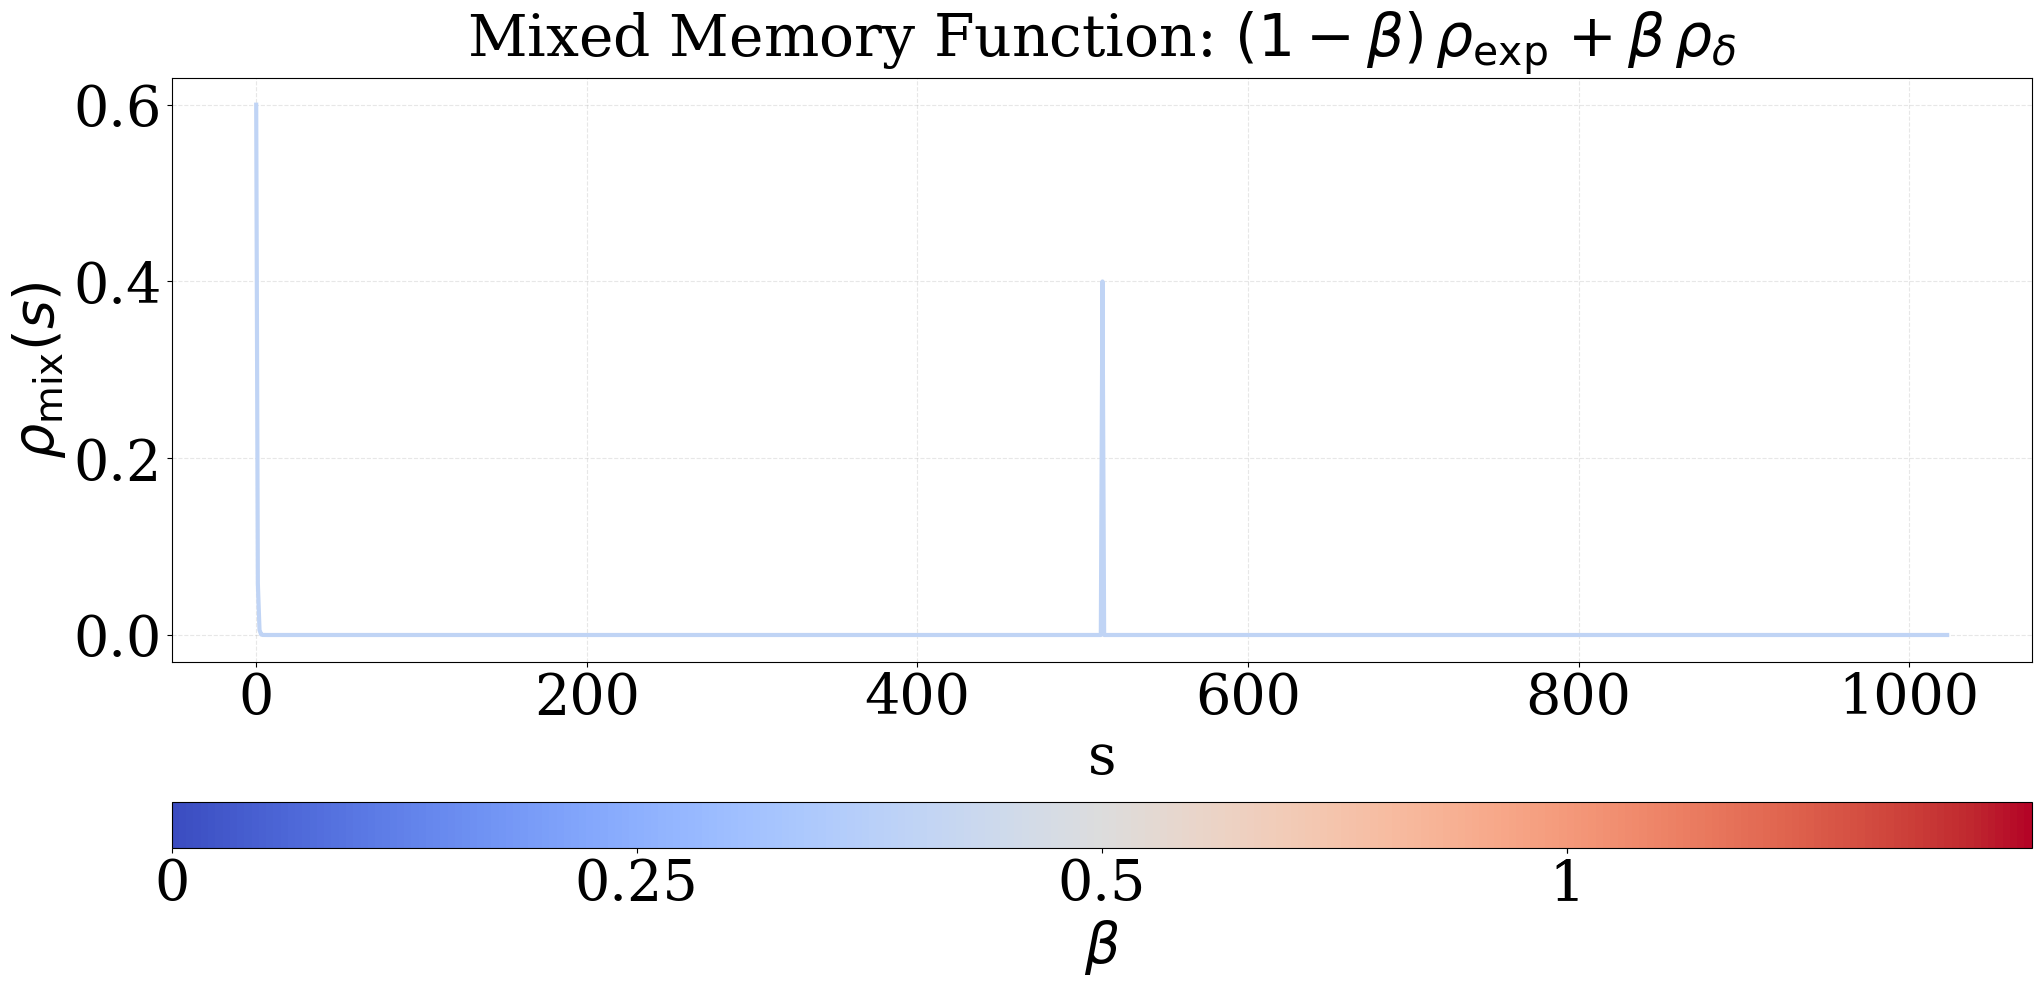

In [9]:
beta_values = [0.4]   # 0.0, 0.1, ..., 1.0
s = np.arange(T, dtype=float)

cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=0, vmax=1)

fig = plt.figure(figsize=(24, 10))
gs = GridSpec(2, 1, figure=fig, height_ratios=[1, 0.1], hspace=0.4)

ax = fig.add_subplot(gs[0, 0])

for beta in beta_values:
    y = mix_exp_impulse(s, beta)
    color = cmap(norm(beta))
    ax.plot(s, y, color=color, linewidth=3)

ax.set_xlabel('s')
ax.set_ylabel(r'$\rho_{\mathrm{mix}}(s)$')
ax.set_title(r'Mixed Memory Function: $(1-\beta)\,\rho_{\exp} + \beta\,\rho_{\delta}$')
ax.grid(True, alpha=0.3)

# Colorbar for beta
ax_cbar = fig.add_subplot(gs[1, 0])
ax_cbar.axis('off')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_cbar, orientation='horizontal',
                    fraction=0.8, aspect=40, pad=0.05)
cbar.set_label(r'$\beta$', fontsize=font_size)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 0.75])
cbar.set_ticklabels(['0', '0.25', '0.5', '0.75', '1'])

plt.savefig('mix_target_memory_function.pdf', dpi=300, bbox_inches='tight')
plt.show()

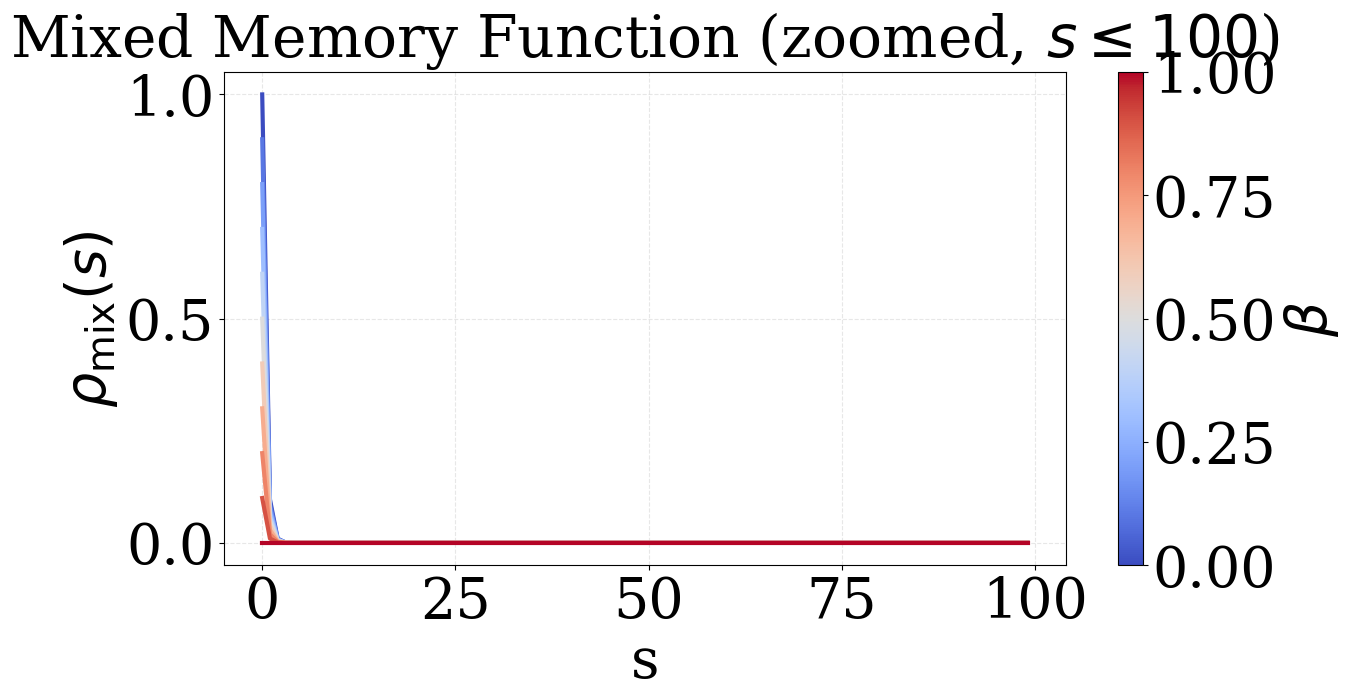

In [3]:
# Zoomed view: first 100 time steps to show exponential decay clearly
fig, ax = plt.subplots(figsize=(14, 8))

for beta in beta_values:
    y = mix_exp_impulse(s, beta)
    color = cmap(norm(beta))
    ax.plot(s[:100], y[:100], color=color, linewidth=3)

ax.set_xlabel('s')
ax.set_ylabel(r'$\rho_{\mathrm{mix}}(s)$')
ax.set_title(r'Mixed Memory Function (zoomed, $s \leq 100$)')
ax.grid(True, alpha=0.3)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax, label=r'$\beta$')
plt.tight_layout()
plt.savefig('mix_target_memory_function_zoom.pdf', dpi=300, bbox_inches='tight')
plt.show()